# Notebook 02: Data Cleaning & Exploratory Data Analysis (EDA)
## AI Fashion Recommendation System

### 1. Stage Overview & Purpose
In this notebook, we transform raw catalog metadata and user demographic data into clean, robust, and reproducible datasets for machine learning.

### 2. Concrete Data Engineering & Cleaning Tasks:
1. **Myntra Dataset Cleaning**:
   - Resolve 193,158 missing `DiscountPrice (in Rs)` values: When items have 0% discount, retail price equals original price (`DiscountPrice = OriginalPrice`).
   - Create an explicit boolean feature `is_discounted`.
   - Calculate exact discount percentage: `calculated_discount_pct = ((OriginalPrice - DiscountPrice) / OriginalPrice) * 100`.
   - Handle missing `Ratings` and `Reviews` (63.84% missing) using missing-indicator flags and median imputation rather than dropping 60% of the catalog.
   - Text cleaning: lowercase, strip punctuation, remove whitespace anomalies in descriptions.
2. **H&M Articles Cleaning**:
   - Zero-pad `article_id` to 10 digits as strings.
   - Impute 416 missing `detail_desc` values with `prod_name + " " + product_type_name`.
   - Standardize fashion slot mapping (`standard_category`: `upper_body`, `lower_body`, `full_body`, `shoes`, `accessories`, `underwear/other`).
3. **Exploratory Data Analysis (EDA)**:
   - Price distribution analysis, skewness, and log-transform evaluation.
   - Category distribution, color palette frequency, and gender segmentation.
   - Visual inspection of catalog garments across standardized slots.
4. **Data Persistence**:
   - Save processed datasets in Apache Parquet format (`data/processed/myntra_cleaned.parquet` and `data/processed/hm_articles_cleaned.parquet`) for fast, typed I/O in subsequent modeling notebooks.


In [1]:
# Standard library and visualization imports
import os
import sys
import time
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: "%.2f" % x)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

print("Analytical libraries loaded successfully for Data Cleaning & EDA!")


Analytical libraries loaded successfully for Data Cleaning & EDA!


## Section 1: File Paths & Configuration

### What we are doing:
We specify source file paths and target destination paths in `data/processed/`.


In [2]:
PROJECT_ROOT = Path(".").resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

MYNTRA_RAW_CSV = PROJECT_ROOT / "archive" / "Myntra Fasion Clothing.csv"
if not MYNTRA_RAW_CSV.exists():
    MYNTRA_RAW_CSV = DATA_RAW_DIR / "Myntra Fasion Clothing.csv"

HM_ARTICLES_RAW_CSV = PROJECT_ROOT / "h-and-m-personalized-fashion-recommendations" / "articles.csv"
HM_CUSTOMERS_RAW_CSV = PROJECT_ROOT / "h-and-m-personalized-fashion-recommendations" / "customers.csv"
HM_IMAGE_DIR = PROJECT_ROOT / "h-and-m-personalized-fashion-recommendations" / "images"

# Target processed files
MYNTRA_PROCESSED_PATH = DATA_PROCESSED_DIR / "myntra_cleaned.parquet"
HM_ARTICLES_PROCESSED_PATH = DATA_PROCESSED_DIR / "hm_articles_cleaned.parquet"

print(f"Source Myntra CSV:     {MYNTRA_RAW_CSV} (Exists: {MYNTRA_RAW_CSV.exists()})")
print(f"Source H&M Articles:   {HM_ARTICLES_RAW_CSV} (Exists: {HM_ARTICLES_RAW_CSV.exists()})")
print(f"Target Processed Dir:  {DATA_PROCESSED_DIR}")


Source Myntra CSV:     H:\datasets\archive\Myntra Fasion Clothing.csv (Exists: True)
Source H&M Articles:   H:\datasets\h-and-m-personalized-fashion-recommendations\articles.csv (Exists: True)
Target Processed Dir:  H:\datasets\data\processed


## Section 2: Myntra Data Cleaning Pipeline

### What we are doing:
1. Impute missing `DiscountPrice (in Rs)` where discount is 0: `DiscountPrice = OriginalPrice`.
2. Compute accurate `discount_pct`: `((OriginalPrice - DiscountPrice) / OriginalPrice) * 100`.
3. Add a boolean flag `is_discounted`.
4. Create an indicator feature `has_rating` (1 if rated, 0 if null) and impute missing ratings with catalog median.
5. Clean textual descriptions by stripping HTML-like entities and trimming whitespace.


In [3]:
# Load raw Myntra catalog
df_myntra = pd.read_csv(MYNTRA_RAW_CSV, low_memory=False)
initial_rows = len(df_myntra)
print(f"Initial raw Myntra rows: {initial_rows:,}")

# 1. Price Cleaning and Imputation
# Where DiscountPrice is missing, item is sold at full OriginalPrice
missing_disc_mask = df_myntra["DiscountPrice (in Rs)"].isna()
df_myntra["DiscountPrice (in Rs)"] = df_myntra["DiscountPrice (in Rs)"].fillna(df_myntra["OriginalPrice (in Rs)"])

# Compute actual discount percentage and discount flag
df_myntra["calculated_discount_pct"] = (
    (df_myntra["OriginalPrice (in Rs)"] - df_myntra["DiscountPrice (in Rs)"]) 
    / df_myntra["OriginalPrice (in Rs)"] * 100
).clip(lower=0.0, upper=100.0)

df_myntra["is_discounted"] = (df_myntra["calculated_discount_pct"] > 0).astype(int)

# 2. Ratings and Reviews Imputation with Missing-Indicator Flag
df_myntra["has_rating"] = df_myntra["Ratings"].notna().astype(int)
median_rating = df_myntra["Ratings"].median()
df_myntra["Ratings_imputed"] = df_myntra["Ratings"].fillna(median_rating)
df_myntra["Reviews_imputed"] = df_myntra["Reviews"].fillna(0)

# 3. Text cleaning on Description
df_myntra["clean_description"] = (
    df_myntra["Description"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# 4. Standard Category Mapping for Myntra
category_mapping = {
    "Topwear": "upper_body",
    "Bottom Wear": "lower_body",
    "Indian Wear": "full_body",
    "Western": "upper_body",
    "Lingerie & Sleep Wear": "underwear",
    "Inner Wear &  Sleep Wear": "underwear",
    "Sports Wear": "upper_body",
    "Plus Size": "full_body"
}
df_myntra["standard_category"] = df_myntra["Category"].map(category_mapping).fillna("other")

print("Myntra Cleaning Applied:")
print(f"  - Imputed Discount Prices: {missing_disc_mask.sum():,}")
print(f"  - Discounted Items: {(df_myntra['is_discounted'] == 1).sum():,} ({df_myntra['is_discounted'].mean()*100:.1f}%)")
print(f"  - Items with Ratings: {(df_myntra['has_rating'] == 1).sum():,} (Median Imputed: {median_rating})")
display(df_myntra[["Product_id", "BrandName", "OriginalPrice (in Rs)", "DiscountPrice (in Rs)", "calculated_discount_pct", "standard_category"]].head(3))


Initial raw Myntra rows: 526,564


Myntra Cleaning Applied:
  - Imputed Discount Prices: 193,158
  - Discounted Items: 333,406 (63.3%)
  - Items with Ratings: 190,412 (Median Imputed: 4.2)


,Product_id,BrandName,OriginalPrice (in Rs),DiscountPrice (in Rs),calculated_discount_pct,standard_category
0,2296012,Roadster,1499.00,824.00,45.03,lower_body
1,13780156,LOCOMOTIVE,1149.00,517.00,55.00,lower_body
2,11895958,Roadster,1399.00,629.00,55.04,upper_body


## Section 3: H&M Articles Cleaning & Slot Taxonomy Mapping

### What we are doing:
1. Ensure `article_id` is a 10-digit zero-padded string.
2. Impute 416 missing descriptions in `detail_desc` using `prod_name` and `product_type_name`.
3. Standardize product groups into standard recommendation slots:
   - `upper_body`: Shirts, T-shirts, Sweaters, Tops, Blouses, Jackets.
   - `lower_body`: Trousers, Shorts, Skirts.
   - `full_body`: Dresses, Jumpsuits, Suits.
   - `shoes`: Boots, Sneakers, Sandals, Flats.
   - `accessories`: Bags, Belts, Hats, Scarves, Sunglasses.
   - `underwear/other`: Underwear, Swimwear, Nightwear.
4. Verify image file paths on disk.


In [4]:
# Load H&M articles
df_articles = pd.read_csv(HM_ARTICLES_RAW_CSV, dtype={"article_id": str})
df_articles["article_id"] = df_articles["article_id"].str.zfill(10)
initial_articles = len(df_articles)

# 1. Impute missing descriptions
missing_desc = df_articles["detail_desc"].isna()
df_articles["detail_desc_clean"] = df_articles["detail_desc"].fillna(
    df_articles["prod_name"] + " " + df_articles["product_type_name"]
)

# 2. Build verified image lookup
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}
image_files = [p for p in HM_IMAGE_DIR.rglob("*") if p.is_file() and p.suffix.lower() in image_extensions]
img_lookup = {p.stem: str(p.relative_to(PROJECT_ROOT)).replace("\\", "/") for p in image_files}
df_articles["image_path"] = df_articles["article_id"].map(img_lookup)
df_articles["has_image"] = df_articles["image_path"].notna().astype(int)

# 3. Standard Category Mapping for Outfit Slot Recommendation
def map_hm_slot(row):
    group = str(row["product_group_name"]).lower()
    ptype = str(row["product_type_name"]).lower()
    
    if "upper body" in group:
        return "upper_body"
    elif "lower body" in group:
        return "lower_body"
    elif "full body" in group:
        return "full_body"
    elif "shoes" in group or "footwear" in group:
        return "shoes"
    elif "accessories" in group or "bags" in group:
        return "accessories"
    elif "underwear" in group or "socks" in group or "nightwear" in group or "swimwear" in group:
        return "underwear"
    else:
        return "other"

df_articles["standard_category"] = df_articles.apply(map_hm_slot, axis=1)

print("H&M Articles Cleaning Summary:")
print(f"  - Total Articles: {len(df_articles):,}")
print(f"  - Imputed Descriptions: {missing_desc.sum():,}")
print(f"  - Verified Images on disk: {df_articles['has_image'].sum():,} ({df_articles['has_image'].mean()*100:.2f}%)")
print("\nStandard Category Distribution:")
display(df_articles["standard_category"].value_counts().to_frame("Count"))


H&M Articles Cleaning Summary:
  - Total Articles: 105,542
  - Imputed Descriptions: 416
  - Verified Images on disk: 105,100 (99.58%)

Standard Category Distribution:


,Count
standard_category,
upper_body,42741
lower_body,19812
full_body,13292
underwear,13012
accessories,11183
shoes,5283
other,219


## Section 4: Exploratory Data Analysis & Visualizations

### What we are doing:
We create insightful exploratory plots examining:
1. Price distributions and log-transformed distributions in Myntra.
2. Discount rate distribution.
3. H&M standard slot category frequencies.
4. Top color families in H&M articles.
5. Sample images across each standard category slot.


C:\Users\Harshal\AppData\Local\Temp\ipykernel_21192\1716682626.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=slot_counts.values, y=slot_counts.index, ax=axes[1, 0], palette="crest")
C:\Users\Harshal\AppData\Local\Temp\ipykernel_21192\1716682626.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_colors.values, y=top_colors.index, ax=axes[1, 1], palette="flare")


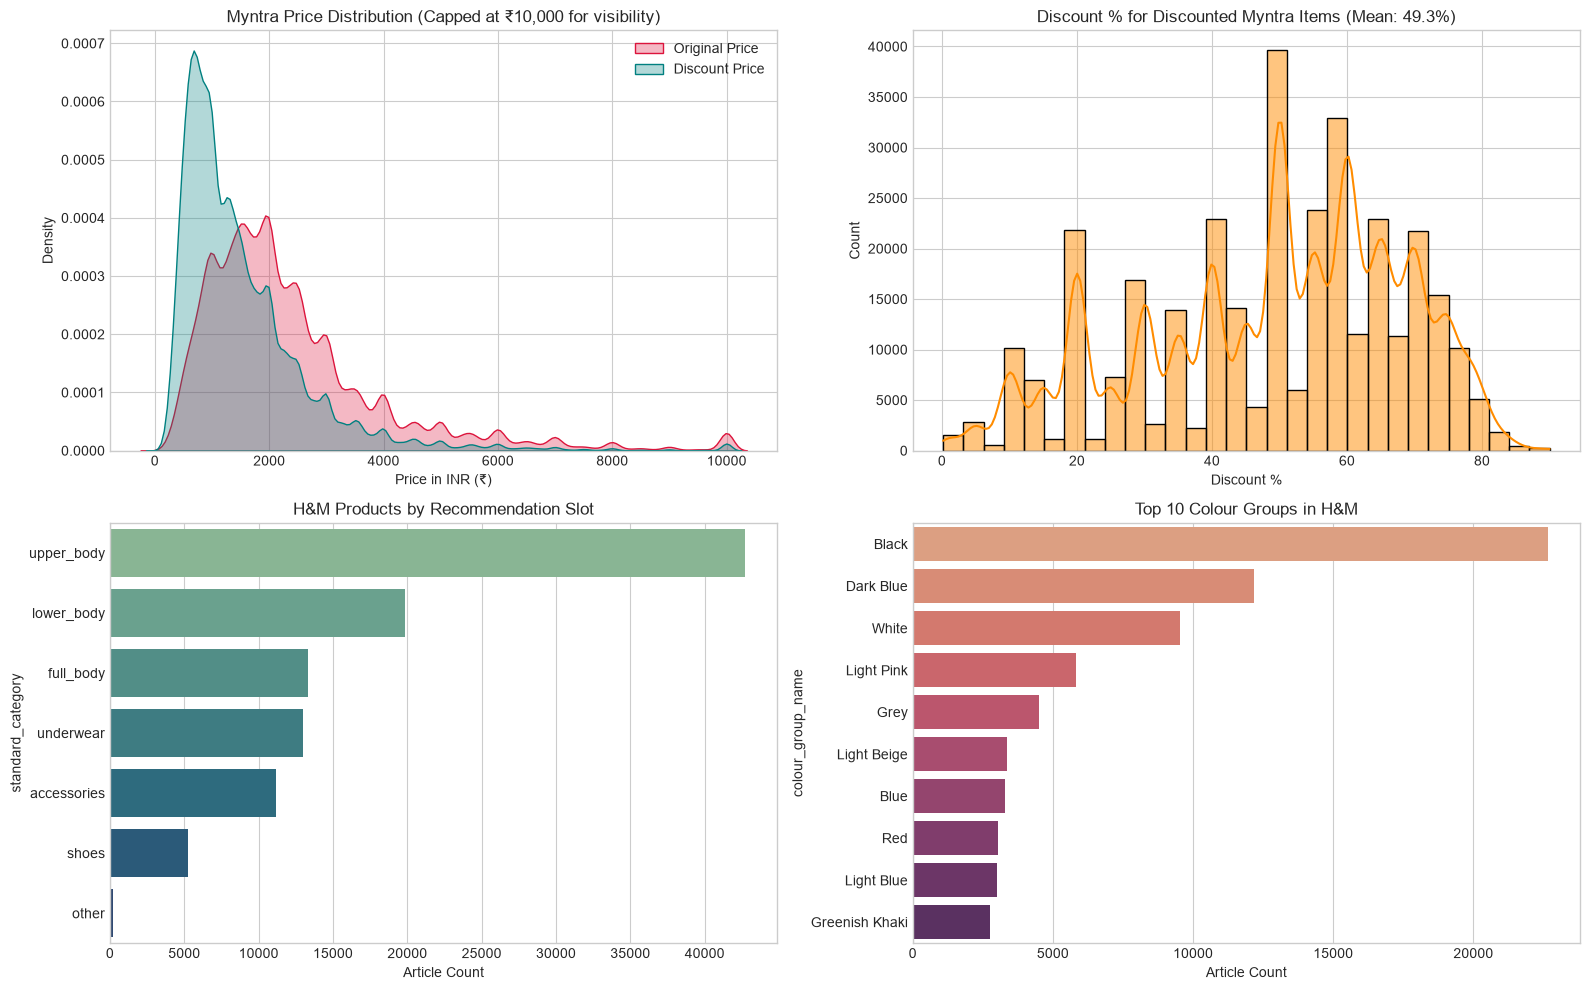

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Price Distribution (Myntra Original vs Discount)
sns.kdeplot(df_myntra["OriginalPrice (in Rs)"].clip(upper=10000), label="Original Price", ax=axes[0, 0], color="crimson", fill=True, alpha=0.3)
sns.kdeplot(df_myntra["DiscountPrice (in Rs)"].clip(upper=10000), label="Discount Price", ax=axes[0, 0], color="teal", fill=True, alpha=0.3)
axes[0, 0].set_title("Myntra Price Distribution (Capped at ₹10,000 for visibility)")
axes[0, 0].set_xlabel("Price in INR (₹)")
axes[0, 0].legend()

# 2. Discount Percentage Distribution
sns.histplot(df_myntra[df_myntra["is_discounted"] == 1]["calculated_discount_pct"], bins=30, ax=axes[0, 1], color="darkorange", kde=True)
axes[0, 1].set_title("Discount % for Discounted Myntra Items (Mean: {:.1f}%)".format(
    df_myntra[df_myntra["is_discounted"] == 1]["calculated_discount_pct"].mean()
))
axes[0, 1].set_xlabel("Discount %")

# 3. H&M Standard Category Slots
slot_counts = df_articles["standard_category"].value_counts()
sns.barplot(x=slot_counts.values, y=slot_counts.index, ax=axes[1, 0], palette="crest")
axes[1, 0].set_title("H&M Products by Recommendation Slot")
axes[1, 0].set_xlabel("Article Count")

# 4. H&M Top Color Palettes
top_colors = df_articles["colour_group_name"].value_counts().head(10)
sns.barplot(x=top_colors.values, y=top_colors.index, ax=axes[1, 1], palette="flare")
axes[1, 1].set_title("Top 10 Colour Groups in H&M")
axes[1, 1].set_xlabel("Article Count")

plt.tight_layout()
plt.show()


### Section 4.1: Visualizing Clothing Slots with Real Images

### What we are doing:
We display real images from the H&M catalog corresponding to the core outfit slots (`upper_body`, `lower_body`, `shoes`, `accessories`, `full_body`).


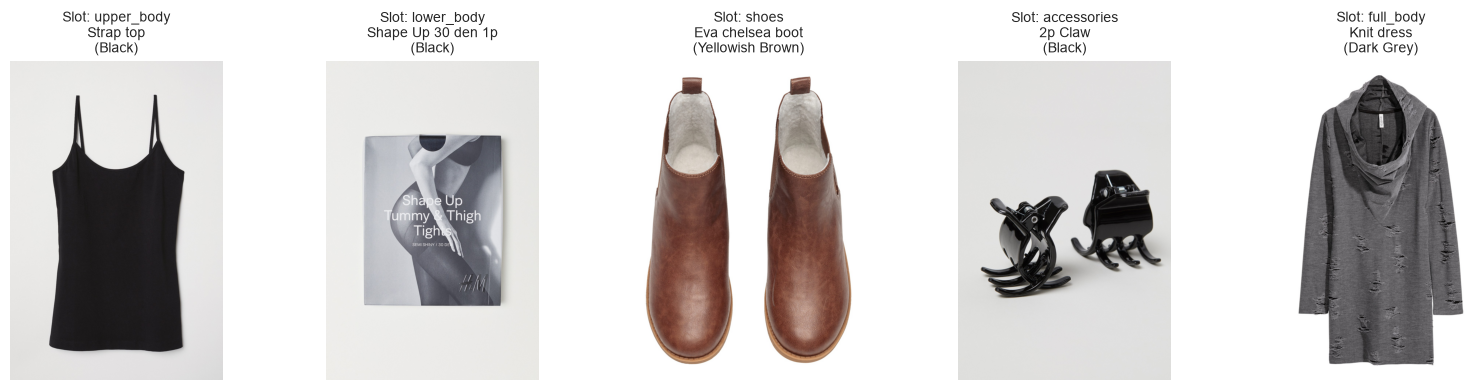

In [6]:
slots_to_sample = ["upper_body", "lower_body", "shoes", "accessories", "full_body"]
sample_items = []

for slot in slots_to_sample:
    matching = df_articles[(df_articles["standard_category"] == slot) & (df_articles["has_image"] == 1)]
    if not matching.empty:
        sample_items.append(matching.iloc[0])

fig, axes = plt.subplots(1, len(sample_items), figsize=(16, 4))
for ax, row in zip(axes, sample_items):
    img_path = PROJECT_ROOT / row["image_path"]
    with Image.open(img_path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"Slot: {row['standard_category']}\n{row['prod_name'][:18]}\n({row['colour_group_name']})", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()


## Section 5: Save Cleaned Datasets to Parquet

### What we are doing:
We export the cleaned dataframes to Apache Parquet format (`data/processed/myntra_cleaned.parquet` and `data/processed/hm_articles_cleaned.parquet`).

### Why Parquet:
- Parquet maintains explicit data types (strings, floats, categories).
- Parquet is compressed and loads up to 10x faster than raw CSVs.
- Downstream modeling notebooks can read clean data without repeating preprocessing.


In [7]:
# Save Myntra cleaned dataset
t0 = time.time()
df_myntra.to_parquet(MYNTRA_PROCESSED_PATH, index=False, engine="pyarrow")
myntra_save_time = time.time() - t0
myntra_mb = os.path.getsize(MYNTRA_PROCESSED_PATH) / (1024 ** 2)
print(f"Saved: {MYNTRA_PROCESSED_PATH} ({myntra_mb:.2f} MB in {myntra_save_time:.2f}s)")

# Save H&M articles cleaned dataset
t0 = time.time()
df_articles.to_parquet(HM_ARTICLES_PROCESSED_PATH, index=False, engine="pyarrow")
hm_save_time = time.time() - t0
hm_mb = os.path.getsize(HM_ARTICLES_PROCESSED_PATH) / (1024 ** 2)
print(f"Saved: {HM_ARTICLES_PROCESSED_PATH} ({hm_mb:.2f} MB in {hm_save_time:.2f}s)")

# Validation of saved files
assert MYNTRA_PROCESSED_PATH.exists() and os.path.getsize(MYNTRA_PROCESSED_PATH) > 0, "Myntra parquet save failed"
assert HM_ARTICLES_PROCESSED_PATH.exists() and os.path.getsize(HM_ARTICLES_PROCESSED_PATH) > 0, "H&M parquet save failed"

print("=" * 60)
print("ALL DATA CLEANING & EDA OPERATIONS COMPLETED SUCCESSFULLY!")
print("Cleaned datasets are ready for Feature Engineering (Notebook 03).")
print("=" * 60)


Saved: H:\datasets\data\processed\myntra_cleaned.parquet (39.36 MB in 0.81s)


Saved: H:\datasets\data\processed\hm_articles_cleaned.parquet (10.12 MB in 0.27s)
ALL DATA CLEANING & EDA OPERATIONS COMPLETED SUCCESSFULLY!
Cleaned datasets are ready for Feature Engineering (Notebook 03).
